# Demo: Will this vulnerability be rated Critical?

**CS383 · Capstone deployment demo.** This notebook walks the capstone workflow end to end on a real dataset, from question to a saved model that `app.py` serves as a live Streamlit app.

**Data:** NVD CVE API 2.0 (National Vulnerability Database, NIST). Pulled with `pull_nvd.py`.
*This product uses data from the NVD API but is not endorsed or certified by the NVD.*

Run `python pull_nvd.py` once in this folder first. It creates `nvd_cves.csv`.

## 1. Define the problem

**Question.** When a vulnerability is first published, can we predict whether it will be rated **Critical** (CVSS v3 score 9.0 or higher) from what we know about it, such as its weakness type (CWE), the vendor, the kind of product, and who reported it?

- **Type:** binary classification. **Target:** `is_critical` = 1 if the CVSS v3 severity is `CRITICAL`, else 0.
- **Candidate features:** `cwe_primary`, `vendor`, `cpe_part` (application / OS / hardware), `source` (who reported it), `pub_year`, `n_references`. Step 5 shows how I decide which ones to keep.
- **Deliberately NOT features:** the CVSS metrics (`base_score`, `attack_vector`, `privileges_required`, ...). The severity rating is *computed from* those metrics, so using them would hand the model the answer. Step 7 shows how big that leak is.

**Why it matters.** A security team facing hundreds of new CVEs a week wants to know which to look at first.

## 2. Collect data

In [1]:
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
raw = pd.read_csv("nvd_cves.csv")
print(raw.shape)
raw.head()

(68769, 20)


,cve_id,published,source,vuln_status,n_references,cwe_primary,cwe_all,vendor,cpe_part,cvss_version,base_score,base_severity,attack_vector,attack_complexity,privileges_required,user_interaction,scope,confidentiality,integrity,availability
0,CVE-2023-0028,2023-01-01T01:15:12.627,security@huntr.dev,Modified,4,CWE-79,CWE-79,linagora,a,3.1,5.4,MEDIUM,NETWORK,LOW,LOW,REQUIRED,CHANGED,LOW,LOW,NONE
1,CVE-2021-41823,2023-01-01T06:15:09.283,cve@mitre.org,Modified,2,CWE-79,CWE-79,kemptechnologies,a,3.1,6.1,MEDIUM,NETWORK,LOW,NONE,REQUIRED,CHANGED,LOW,LOW,NONE
2,CVE-2022-47952,2023-01-01T06:15:09.860,cve@mitre.org,Modified,10,CWE-203,CWE-203,linuxcontainers,a,3.1,3.3,LOW,LOCAL,LOW,LOW,NONE,UNCHANGED,LOW,NONE,NONE
3,CVE-2022-48198,2023-01-01T07:15:10.187,cve@mitre.org,Modified,6,CWE-668,CWE-668,ntpd_driver_project,a,3.1,9.8,CRITICAL,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH
4,CVE-2022-34322,2023-01-01T08:15:10.007,cve@mitre.org,Modified,2,CWE-79,CWE-79,sage,a,3.1,9.0,CRITICAL,NETWORK,LOW,LOW,REQUIRED,CHANGED,HIGH,HIGH,HIGH


**Provenance.** The NVD is run by NIST. Each row is one CVE record: an identifier for a publicly disclosed vulnerability, enriched by NVD analysts with a CVSS score, weakness type (CWE), and affected products (CPE). `pull_nvd.py` flattens the nested JSON from the API into one row per CVE and skips records with status *Rejected*.

In [2]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68769 entries, 0 to 68768
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   cve_id               68769 non-null  object 
 1   published            68769 non-null  object 
 2   source               68769 non-null  object 
 3   vuln_status          68769 non-null  object 
 4   n_references         68769 non-null  int64  
 5   cwe_primary          67975 non-null  object 
 6   cwe_all              67975 non-null  object 
 7   vendor               61007 non-null  object 
 8   cpe_part             61007 non-null  object 
 9   cvss_version         68444 non-null  float64
 10  base_score           68444 non-null  float64
 11  base_severity        68444 non-null  object 
 12  attack_vector        68444 non-null  object 
 13  attack_complexity    68444 non-null  object 
 14  privileges_required  68444 non-null  object 
 15  user_interaction     68444 non-null 

## 3. Clean the data

Real data has issues. Three here, each handled and explained.

In [3]:
df = raw.copy()

# Issue 1: duplicate CVE IDs (a resumed pull can re-read a window)
print("duplicate cve_id rows:", df.duplicated("cve_id").sum())
df = df.drop_duplicates("cve_id")

# Issue 2: no CVSS v3 rating -> no target. A few CVEs are not scored yet, and CVEs from before 2016
# only have v2 (which has no 'Critical' level).
print("rows with no v3 severity:", df["base_severity"].isna().sum(), "of", len(df))
df = df.dropna(subset=["base_severity"]).copy()

# Issue 3: missing categorical values. Blank vendor = NVD has no product list for the CVE yet.
for col in ["cwe_primary", "vendor", "cpe_part", "source"]:
    print(f"{col}: {df[col].isna().sum()} missing")
    df[col] = df[col].fillna("unknown")

df["pub_year"] = pd.to_datetime(df["published"]).dt.year
df["is_critical"] = (df["base_severity"] == "CRITICAL").astype(int)
print(df.shape)

duplicate cve_id rows: 0
rows with no v3 severity: 325 of 68769
cwe_primary: 787 missing
vendor: 7438 missing
cpe_part: 7438 missing
source: 0 missing
(68444, 22)


1. **Duplicates** were dropped (keep one row per CVE).
2. **No v3 rating** means no label, so those rows are dropped. It is a small share of this 2023–2024 data (see the count above), but the model still only describes CVEs that *were* scored under v3.
3. **Missing categories** were filled with the label `unknown` instead of dropped, because "NVD has no product data yet" is itself information.

## 4. Explore the data

base_severity
MEDIUM      32328
HIGH        25321
CRITICAL     9566
LOW          1228
NONE            1
Name: count, dtype: int64

Critical share: 14.0%
distinct weakness types: 493 | distinct vendors: 8952


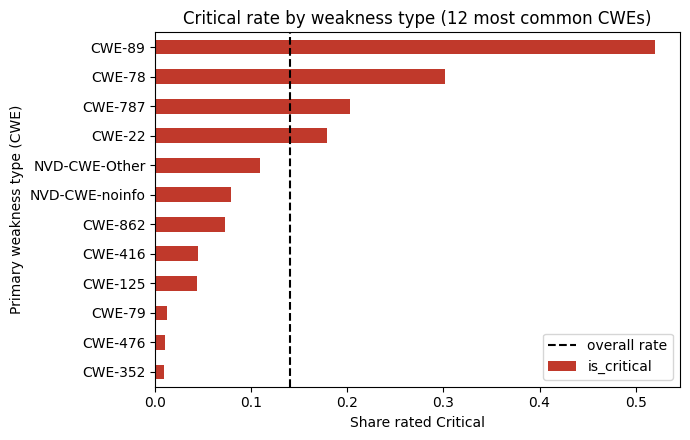

In [4]:
print(df["base_severity"].value_counts())
print(f"\nCritical share: {df['is_critical'].mean():.1%}")
print("distinct weakness types:", df["cwe_primary"].nunique(), "| distinct vendors:", df["vendor"].nunique())

top = df["cwe_primary"].value_counts().head(12).index
rate = df[df["cwe_primary"].isin(top)].groupby("cwe_primary")["is_critical"].mean().sort_values()
ax = rate.plot.barh(figsize=(7, 4.5), color="#c0392b")
ax.axvline(df["is_critical"].mean(), color="black", ls="--", label="overall rate")
ax.set_xlabel("Share rated Critical")
ax.set_ylabel("Primary weakness type (CWE)")
ax.set_title("Critical rate by weakness type (12 most common CWEs)")
ax.legend()
plt.tight_layout()
plt.show()

**What it shows and how it affects choices.** Critical is a minority class, so plain accuracy will look good even for a model that never predicts Critical. We will judge models with **F1 and ROC AUC** and compare against a baseline. The Critical rate usually differs a lot across weakness types (compare injection or file-upload flaws with cross-site scripting in your chart), so `cwe_primary` should carry real signal. `vendor` has thousands of values, so the encoder will group rare ones together.

## 5. Choose the features and build a model

Split **first**. Choosing features is a modeling decision too, so I make it using the **training set only**. If I peeked at the test set while choosing, the final test score would be optimistic.

In [5]:
ALL_CAT = ["cwe_primary", "vendor", "cpe_part", "source"]
ALL_NUM = ["pub_year", "n_references"]
y = df["is_critical"]
X_train_all, X_test_all, y_train, y_test = train_test_split(
    df[ALL_CAT + ALL_NUM], y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train_all.shape, X_test_all.shape, f"critical share train {y_train.mean():.1%} / test {y_test.mean():.1%}")


def make_pipeline(model, cat, num=()):
    # min_frequency groups rare vendors/CWEs into one 'infrequent' bucket; unseen values at predict time
    # (a brand-new vendor in the app) go to that bucket instead of crashing.
    # Numeric columns are scaled: otherwise a column like n_references next to thousands of 0/1 columns
    # makes logistic regression's optimizer converge very slowly.
    steps = []
    if cat:
        steps.append(("cat", OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist"), list(cat)))
    if num:
        steps.append(("num", StandardScaler(), list(num)))
    return Pipeline([("prep", ColumnTransformer(steps)), ("model", model)])

(54755, 6) (13689, 6) critical share train 14.0% / test 14.0%


### How I pick features: four questions, in this order

1. **Would I know it at prediction time?** If not, it is leakage, however helpful it looks.
2. **Is it usable?** How much is missing, and how many distinct values does it have?
3. **Does it carry signal on its own?** Score a model that sees only that feature.
4. **Does it still help when everything else is already in the model?** Remove it and see what is lost. A feature can look useful alone but add nothing because another feature already says the same thing.

Questions 1 and 2 can be answered by thinking and counting. Questions 3 and 4 need cross-validation, run on the training set.

**Question 1: availability.** I start from every column and cross some off before measuring anything.

In [6]:
pd.set_option("display.max_colwidth", None)
candidates = pd.DataFrame([
    ("cve_id",                         "yes",    "drop",  "An identifier: unique in every row, so there is nothing to learn."),
    ("vuln_status",                    "no",     "drop",  "Set during NVD processing. It describes the paperwork, not the vulnerability."),
    ("base_score and the CVSS metrics", "no",    "drop",  "Severity is computed from them. Step 7 shows the leak."),
    ("cwe_all",                        "yes",    "drop",  "Mostly repeats cwe_primary. Keep one."),
    ("cwe_primary",                    "yes",    "test",  "Weakness type."),
    ("vendor",                         "yes",    "test",  "Who makes the product."),
    ("cpe_part",                       "yes",    "test",  "Application, operating system, or hardware."),
    ("source",                         "yes",    "test",  "Which organization reported it."),
    ("pub_year",                       "yes",    "test",  "Year published."),
    ("n_references",                   "partly", "test",  "The link list can keep growing after publication."),
], columns=["column", "known at prediction time?", "first decision", "why"])
candidates

,column,known at prediction time?,first decision,why
0,cve_id,yes,drop,"An identifier: unique in every row, so there is nothing to learn."
1,vuln_status,no,drop,"Set during NVD processing. It describes the paperwork, not the vulnerability."
2,base_score and the CVSS metrics,no,drop,Severity is computed from them. Step 7 shows the leak.
3,cwe_all,yes,drop,Mostly repeats cwe_primary. Keep one.
4,cwe_primary,yes,test,Weakness type.
5,vendor,yes,test,Who makes the product.
6,cpe_part,yes,test,"Application, operating system, or hardware."
7,source,yes,test,Which organization reported it.
8,pub_year,yes,test,Year published.
9,n_references,partly,test,The link list can keep growing after publication.


**Question 2: usability.**

In [7]:
rows = []
for c in ALL_CAT:
    rows.append((c, (X_train_all[c] == "unknown").mean(), X_train_all[c].nunique()))
for c in ALL_NUM:
    rows.append((c, 0.0, X_train_all[c].nunique()))
pd.DataFrame(rows, columns=["feature", "share unknown", "distinct values"]).set_index("feature").round(3)

,share unknown,distinct values
feature,,
cwe_primary,0.011,463
vendor,0.110,7918
cpe_part,0.110,4
source,0.000,316
pub_year,0.000,2
n_references,0.000,64


`vendor` has thousands of values and is unknown for roughly one CVE in ten, so the encoder will group the rare ones. `pub_year` has only **two** values, so a model cannot learn a trend from it, and in a deployed app any future year would be outside everything it has seen. Neither is disqualifying yet, so they go on to the measured tests.

**Question 3: signal on its own.** Each feature goes into its own small model. ROC AUC of 0.5 is a coin flip.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
alone = {}
with warnings.catch_warnings():
    # On some Macs numpy prints harmless floating-point RuntimeWarnings for these tiny one-column fits.
    warnings.simplefilter("ignore", RuntimeWarning)
    for f in ALL_CAT + ALL_NUM:
        pipe = make_pipeline(LogisticRegression(max_iter=2000),
                             cat=[f] if f in ALL_CAT else [], num=[f] if f in ALL_NUM else [])
        alone[f] = cross_val_score(pipe, X_train_all, y_train, cv=cv, scoring="roc_auc").mean()
pd.Series(alone, name="AUC alone").sort_values(ascending=False).round(3)

cwe_primary     0.823
source          0.750
vendor          0.719
pub_year        0.539
cpe_part        0.528
n_references    0.467
Name: AUC alone, dtype: float64

Weakness type is the strongest on its own, with vendor and source in the middle. The product type, the year, and the reference count sit close to 0.5, so they tell us little by themselves.

**Question 4: does it still help when the others are present?** Remove one feature at a time, from a quick random forest, and look at the cost. I also need to know how much the score moves by chance, so I measure the **fold-to-fold noise**: the standard deviation of the five cross-validation AUCs. A change smaller than that is not a real difference.

In [9]:
def quick_rf():
    return RandomForestClassifier(n_estimators=100, min_samples_leaf=3, class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=RANDOM_STATE)

def cv_auc(cat, num):
    return cross_val_score(make_pipeline(quick_rf(), cat=cat, num=num), X_train_all, y_train, cv=cv, scoring="roc_auc")

all_scores = cv_auc(ALL_CAT, ALL_NUM)
noise = all_scores.std()
aucs = {"all six features": all_scores.mean()}
for f in ALL_CAT + ALL_NUM:
    aucs[f"without {f}"] = cv_auc([c for c in ALL_CAT if c != f], [n for n in ALL_NUM if n != f]).mean()
drop_one = pd.DataFrame({"AUC": aucs})
drop_one["change vs. all six"] = drop_one["AUC"] - all_scores.mean()
print(f"fold-to-fold noise (std of the 5 AUCs): {noise:.4f}")
drop_one.round(4)

fold-to-fold noise (std of the 5 AUCs): 0.0029


,AUC,change vs. all six
all six features,0.8760,0.0000
without cwe_primary,0.7853,-0.0907
without vendor,0.8697,-0.0063
without cpe_part,0.8755,-0.0005
without source,0.8656,-0.0103
without pub_year,0.8749,-0.0010
without n_references,0.8744,-0.0016


**Decision rule.** If removing a feature costs less than the noise, it is not earning its place, and the simpler model wins: fewer inputs to collect, fewer things to break in the app. Applying that to the table: weakness type is worth far more than anything else, and `source` and `vendor` each cost more than the noise when removed. `cpe_part`, `pub_year` and `n_references` each cost less than the noise, so they go. `pub_year` and `n_references` also had the extra problems we saw (two values only; a list that grows after publication), which would have been reasons to be careful even if they had helped a little.

This is a rule of thumb, not a law, and it is based on one dataset and one random split, so I check the reduced model against the full one.

In [10]:
CAT = ["cwe_primary", "vendor", "source"]     # decision from the tables above
NUM = []
FEATURES = CAT + NUM
X_train, X_test = X_train_all[FEATURES], X_test_all[FEATURES]

reduced = cv_auc(CAT, NUM)
print(f"{len(FEATURES)} features: AUC {reduced.mean():.4f}   all six: AUC {all_scores.mean():.4f}   (noise +/- {noise:.4f})")

models = {
    "Baseline (most frequent)": make_pipeline(DummyClassifier(strategy="most_frequent"), cat=CAT, num=NUM),
    "Logistic regression": make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"), cat=CAT, num=NUM),
    "Random forest": make_pipeline(RandomForestClassifier(
        n_estimators=200, min_samples_leaf=3, class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE), cat=CAT, num=NUM),
}

3 features: AUC 0.8724   all six: AUC 0.8760   (noise +/- 0.0029)


The three-feature model scores within about one noise-width of the six-feature one, so I keep the simpler model and build the baseline and two real models on it.

## 6. Evaluate (5-fold cross-validation on the training set)

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = {}
for name, pipe in models.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1", "roc_auc"])
    rows[name] = {k: s[f"test_{k}"].mean() for k in ["accuracy", "f1", "roc_auc"]}
results = pd.DataFrame(rows).T.round(3)
results

,accuracy,f1,roc_auc
Baseline (most frequent),0.860,0.000,0.500
Logistic regression,0.767,0.496,0.866
Random forest,0.780,0.505,0.873


The baseline shows why accuracy alone misleads: predicting "not Critical" every time scores high accuracy but an F1 of 0 and an AUC of 0.5. A real model has to beat it on **F1 and AUC**.

Best by cross-validated F1: Random forest
              precision    recall  f1-score   support

not critical       0.96      0.78      0.86     11776
    critical       0.38      0.82      0.52      1913

    accuracy                           0.79     13689
   macro avg       0.67      0.80      0.69     13689
weighted avg       0.88      0.79      0.82     13689



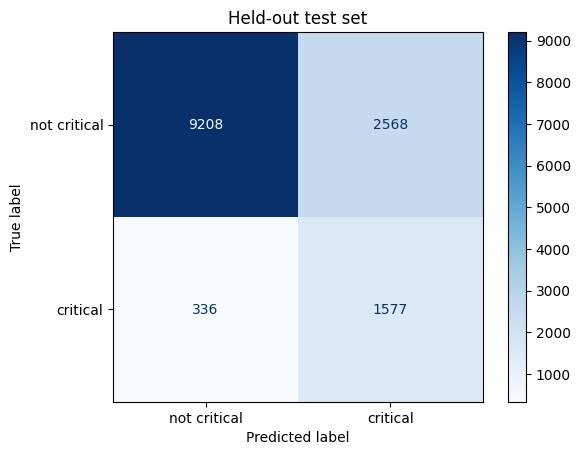

In [12]:
best_name = results.drop(index="Baseline (most frequent)")["f1"].idxmax()
print("Best by cross-validated F1:", best_name)

# The test set is used ONCE, for the model we picked.
final = models[best_name].fit(X_train, y_train)
pred = final.predict(X_test)
print(classification_report(y_test, pred, target_names=["not critical", "critical"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["not critical", "critical"], cmap="Blues")
plt.title("Held-out test set")
plt.show()

**Reading it.** Compare the test F1 with the cross-validated F1. They should be close; a big gap would mean the model was tuned to the training data. The model is a triage aid, not a verdict: weakness type and vendor explain part of severity, but the details of *how* a bug can be exploited are what actually drive the CVSS score, and we do not have those at prediction time.

## 7. The leakage trap

What if we add the CVSS metrics as features? Severity is computed from them, so the model can "predict" it almost perfectly. That would look like a great result and be useless, because those metrics are only known *after* someone has already rated the vulnerability.

In [13]:
leaky = ["base_score", "attack_vector", "attack_complexity", "privileges_required",
         "user_interaction", "scope", "confidentiality", "integrity", "availability"]
df_leaky = df.copy()
for c in leaky[1:]:
    df_leaky[c] = df_leaky[c].fillna("unknown")
Xl = df_leaky[FEATURES + leaky]
Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    Xl, df_leaky["is_critical"], test_size=0.2, stratify=df_leaky["is_critical"], random_state=RANDOM_STATE)

leaky_pipe = make_pipeline(
    RandomForestClassifier(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE),
    cat=CAT + leaky[1:], num=NUM + ["base_score"])
s = cross_validate(leaky_pipe, Xl_train, yl_train, cv=cv, scoring=["f1", "roc_auc"])
print(f"With CVSS metrics:    F1 {s['test_f1'].mean():.3f}   AUC {s['test_roc_auc'].mean():.3f}   <- too good to be true")
print(f"Honest model (above): F1 {results.loc[best_name, 'f1']:.3f}   AUC {results.loc[best_name, 'roc_auc']:.3f}")

With CVSS metrics:    F1 0.999   AUC 1.000   <- too good to be true
Honest model (above): F1 0.505   AUC 0.873


When a score jumps from decent to near perfect, ask what the model can see that it would not have at prediction time. The honest number is the lower one.

## 8. Save the model for deployment

`app.py` needs two files from this notebook: the fitted pipeline, and a small JSON with the choices to show in the dropdowns. The pipeline contains the encoder, so the app passes in raw values and gets a prediction.

In [14]:
joblib.dump(final, "critical_model.joblib")

options = {
    "cwe_primary": df["cwe_primary"].value_counts().head(40).index.tolist(),
    "vendor": df["vendor"].value_counts().head(60).index.tolist(),
    "source": df["source"].value_counts().head(15).index.tolist(),
    "years": [int(df["pub_year"].min()), int(df["pub_year"].max())],
    "best_model": best_name,
    "test_f1": round(float((classification_report(y_test, pred, output_dict=True))["1"]["f1-score"]), 3),
    "critical_share": round(float(df["is_critical"].mean()), 3),
}
with open("app_options.json", "w") as fh:
    json.dump(options, fh, indent=2)

# Sanity check: reload the saved file and predict one made-up CVE, exactly as the app will.
reloaded = joblib.load("critical_model.joblib")
example = pd.DataFrame([{"cwe_primary": "CWE-89", "vendor": "wordpress", "source": options["source"][0]}])
print("P(critical) for the example:", round(float(reloaded.predict_proba(example)[0, 1]), 3))

import sklearn
print("scikit-learn", sklearn.__version__, "<- put this exact version in requirements.txt")

P(critical) for the example: 0.879
scikit-learn 1.7.2 <- put this exact version in requirements.txt


**Next:** run `streamlit run app.py` locally, then follow the deployment slides: push this folder to GitHub (including `critical_model.joblib` and `app_options.json`, but not the big CSV) and create the app on Streamlit Community Cloud.

**Limits worth saying out loud in your own project.** Only CVEs with a v3 rating are modeled. Labels come from an analyst's judgment, not a ground truth. The model sees weakness type and vendor but not the exploit details that drive severity. Rating practices also change over time, so a model trained on 2023–2024 may drift. And the weakness type and product data on a CVE can be filled in by NVD analysts at about the same time as the score, so a true day-one version of this model should rely only on what the reporting organization supplies.